# Building generative models

This notebook is a companion to the official
[`3.generative_model.ipynb`](https://github.com/instadeepai/stix/blob/main/tutorials/notebooks/3.generative_model.ipynb).
It keeps the **same English section numbering and headings** as the official tutorial, but replaces the model with a
**Cosine-VP Diffusion model with DDIM sampling** — a generative model that is *not* one of the models provided by
`stix`.

In the official notebook the `GenerativeModel` is a central object: `get_loss` defines what the network predicts, and
that choice determines the sample-time conversions in `get_generator` (`Velocity` / `VelocityAndScore` generators).
Every model built there is derived from a
[`OneSidedLinearStochasticInterpolant`](https://instadeepai.github.io/stix/api_reference/core/interpolant.html#stix.core.interpolant.OneSidedLinearStochasticInterpolant):

$$
\text{one-sided linear: } z_t = \beta_t z_{\mathrm{tgt}} + \gamma_t \epsilon,
\qquad
\text{flow matching: } z_t = t\, z_{\mathrm{tgt}} + (1-t)\,\epsilon .
$$

The official models differ only in **what the network predicts** ($z_{\mathrm{tgt}}$, `epsilon`, or per-modality
velocity + logits) and in how that output is converted into velocity and score:

| Official section | Model | Network predicts |
| --- | --- | --- |
| 3.1 | `DenoiserGenerativeModel` / `ConverterDenoiserGenerativeModel` | clean target `z_tgt` |
| 3.2 | `NoisePredictionGenerativeModel` (cf. `NoiseOneSidedGenerativeModel`) | noise `epsilon` |
| 3.3 | `HybridVelocityLogitsGenerativeModel` | velocity (continuous) + logits (discrete) |

Here we keep `epsilon`-prediction but change the **interpolation path itself** to a variance-preserving (VP) cosine
schedule, $z_t = \sqrt{\bar\alpha_t}\, x_0 + \sqrt{1-\bar\alpha_t}\,\epsilon$, and replace the ODE/SDE sampler with a
deterministic **DDIM** inversion. Path, objective and sampler therefore all differ from the official models — even
from the official 3.2 noise-prediction model. The implementation is self-contained JAX/Flax and does not import
`stix`, so it runs without the library installed.

## Structure of the notebook

1. Imports
2. Dataloader, `ModalityRegistry`, and `Network`
    1. Dataloader
    2. `ModalityRegistry`
    3. `Network`
3. `GenerativeModel`
    1. Simple denoiser model
    2. Simple noise prediction model
    3. Advanced hybrid (velocity and logits) model

### How the sections correspond

| Official section | This notebook, same section | What is done here instead |
| --- | --- | --- |
| 0. Installation | 0. Installation | Install `jax flax optax matplotlib` rather than `stix-ml` (self-contained). |
| 1. Imports | 1. Imports | Import JAX/Flax/Optax instead of a slice of `stix`. |
| 2.1 Dataloader | 2.1 Dataloader | Same 2D 4-component GMM, `coordinates` only (the official `index` modality is dropped). |
| 2.2 `ModalityRegistry` | 2.2 `ModalityRegistry` | No registry; the interpolant role is taken by the cosine VP schedule. |
| 2.3 `Network` | 2.3 `Network` | A Fourier-time-embedded `ScoreMLP` instead of the cross-modal backbone + heads. |
| 3. `GenerativeModel` | 3. `GenerativeModel` | `diffusion_loss` / `ddim_sample` play the roles of `get_loss` / `get_generator`. |
| 3.1 Denoiser | 3.1 Denoiser | Reviewed as the baseline we deliberately move away from; derive `x0` from `epsilon`. |
| 3.2 Noise prediction | 3.2 Noise prediction | Same target, **different interpolant and sampler**; the loss and training live here. |
| 3.3 Advanced hybrid | 3.3 Advanced hybrid | Single-modality model, so the advanced counterpart is the DDIM sampler + verification. |

> **Correction to an earlier description:** the official notebook is a tutorial on *subclassing* `GenerativeModel`
> (denoiser, converter, noise-prediction and hybrid variants over `FlowMatchingOneSidedInterpolant`); it does not run
> a 3000-step training loop. Training is covered in `1.training_and_sampling.ipynb`. The numbers below come from
> this notebook's own executed run.

## 0. Installation

The official notebook recommends a fresh virtual environment and installs `stix` from PyPI. This notebook is
self-contained, so it needs only the JAX stack. In a fresh environment, from the directory containing this file:

```bash
python -m venv my_env
source my_env/bin/activate
pip install notebook ipykernel jax flax optax matplotlib
python -m ipykernel install --user --name my_env --display-name "my_env"
jupyter notebook
```

The cell below verifies the required packages are importable. Uncomment the `pip` line if you are running in a fresh
environment.

In [1]:
# In a fresh environment, uncomment the next line first:
# %pip install -q jax flax optax matplotlib

import importlib
for _name in ("jax", "flax", "optax", "numpy", "matplotlib", "nbformat"):
    _mod = importlib.import_module(_name)
    print(f"{_name:12s} -> {getattr(_mod, '__version__', 'ok')}")

jax          -> 0.12.1
flax         -> 0.12.12
optax        -> 0.2.9
numpy        -> 2.5.5


matplotlib   -> 3.11.2


nbformat     -> 5.11.1


## 1. Imports

The official notebook only needs a slice of `stix` here. We need a slice of the JAX ecosystem instead.

In [2]:
%matplotlib inline
import math
import numpy as np
import jax
import jax.numpy as jnp
import flax
from flax import nnx
import optax
import matplotlib.pyplot as plt

print("jax   :", jax.__version__)
print("flax  :", flax.__version__)
print("optax :", optax.__version__)
print("numpy :", np.__version__)
print("devices:", jax.devices())

jax   : 0.12.1
flax  : 0.12.12
optax : 0.2.9
numpy : 2.5.5
devices: [CpuDevice(id=0)]


## 2. Dataloader, [`ModalityRegistry`](https://instadeepai.github.io/stix/api_reference/core/modality.html#stix.core.modality.ModalityRegistry), [`Network`](https://instadeepai.github.io/stix/api_reference/nn/network.html#stix.nn.Network)

In the official tutorial these three components initialise a `GenerativeModel`: the `ModalityRegistry` is the
single source of truth for the pytree of modalities and owns each modality's `Embedder` and `Interpolant`, and the
`Network` satisfies the `network(z_t, t, context_data, context_mask, attention_mask)` contract.

Our model is single-modality and self-contained, so we fill the same three roles with: a minimal GMM dataloader, a
cosine VP **schedule** (the interpolant role), and a `ScoreMLP` (the network role). Section 3 then supplies the
`get_loss` / `get_generator` equivalents.

### 2.1 Dataloader

The official dataloader samples two modalities from a Gaussian mixture model — `coordinates` (2D position) and
`index` (the mixture component). Understanding the data is not the point of this tutorial, so we keep only
`coordinates`: four components centred at $(\pm 2, \pm 2)$ with standard deviation $0.35$. See
[`2.grain_multimodal_dataloading.ipynb`](https://github.com/instadeepai/stix/blob/main/tutorials/notebooks/2.grain_multimodal_dataloading.ipynb)
for the full `grain` dataloader setup.

In [3]:
BATCH_SIZE = 256
CENTERS = jnp.array([[2.0, 2.0], [-2.0, 2.0], [-2.0, -2.0], [2.0, -2.0]])
CENTERS_NP = np.asarray(CENTERS)


def sample_gmm(key, batch):
    """Minimal dataloader: 2D coordinates from a 4-component GMM."""
    k1, k2 = jax.random.split(key)
    idx = jax.random.randint(k1, (batch,), 0, 4)
    return CENTERS[idx] + 0.35 * jax.random.normal(k2, (batch, 2))


_probe_batch = sample_gmm(jax.random.PRNGKey(0), BATCH_SIZE)
print("batch shape:", _probe_batch.shape,
      " mean:", np.round(np.asarray(_probe_batch.mean(0)), 3),
      " std :", np.round(np.asarray(_probe_batch.std(0)), 3))
assert _probe_batch.shape == (BATCH_SIZE, 2)

batch shape: (256, 2)  mean: [-0.098  0.054]  std : [2.072 2.005]


### 2.2  [`ModalityRegistry`](https://instadeepai.github.io/stix/api_reference/core/modality.html#stix.core.modality.ModalityRegistry)

For a reminder of how the registry works, the official notebook refers the reader to
`1.training_and_sampling.ipynb`. Here we do **not** build a registry; instead this section defines the interpolant
that the registry would otherwise own.

The official models use `FlowMatchingOneSidedInterpolant`, i.e. $z_t = t z_{\mathrm{tgt}} + (1-t)\epsilon$. We use a
**variance-preserving cosine schedule**:

$$
\bar\alpha(t) = \frac{\cos^2\!\big(\frac{t+s}{1+s}\cdot\frac{\pi}{2}\big)}{\cos^2\!\big(\frac{s}{1+s}\cdot\frac{\pi}{2}\big)},\quad s=0.008,
\qquad
z_t = \sqrt{\bar\alpha_t}\, x_0 + \sqrt{1-\bar\alpha_t}\,\epsilon .
$$

$\bar\alpha(0)=1$ exactly (clean data) and $\bar\alpha(1)=0$ (pure noise); the lower bound is clipped to `1e-3`
so $1/\sqrt{\bar\alpha}$ cannot explode. An exact $\bar\alpha(0)=1$ matters: it makes the noise term vanish on the
last DDIM step instead of leaving residual noise in the samples.

In [4]:
EPS = 1e-8
ABAR_MIN = 1e-3
COSINE_S = 0.008


def cosine_alpha_bar(t):
    """Normalised cosine schedule: t=0 -> 1.0, t=1 -> 0.0."""
    t = jnp.clip(t, 0.0, 1.0)
    f = jnp.cos((t + COSINE_S) / (1.0 + COSINE_S) * math.pi / 2.0) ** 2
    f0 = math.cos(COSINE_S / (1.0 + COSINE_S) * math.pi / 2.0) ** 2
    return f / f0


def alpha_bar(t):
    return jnp.clip(cosine_alpha_bar(t), ABAR_MIN, 1.0)


def diffuse(x0, t, noise):
    """Forward noising: z_t = sqrt(a) * x0 + sqrt(1-a) * eps."""
    a = alpha_bar(t)[..., None]
    z_t = jnp.sqrt(a) * x0 + jnp.sqrt(1.0 - a) * noise
    return z_t, noise


for _t in (0.0, 0.25, 0.5, 0.75, 1.0):
    _a = float(alpha_bar(jnp.array(_t)))
    print(f"t={_t:.2f}  alpha_bar={_a:.6f}  sqrt(1-a)={math.sqrt(max(0.0, 1 - _a)):.4f}")

# Self-check: t=0 must be clean data, t=1 must be (near) pure noise.
_x = jnp.ones((4, 2))
_z = jnp.zeros((4, 2))
assert jnp.allclose(diffuse(_x, jnp.zeros(4), _z)[0], _x)
assert float(alpha_bar(jnp.array(1.0))) < 0.01
print("schedule self-check: PASS")

t=0.00  alpha_bar=1.000000  sqrt(1-a)=0.0002
t=0.25  alpha_bar=0.847012  sqrt(1-a)=0.3911
t=0.50  alpha_bar=0.493844  sqrt(1-a)=0.7114
t=0.75  alpha_bar=0.144272  sqrt(1-a)=0.9251
t=1.00  alpha_bar=0.001000  sqrt(1-a)=0.9995


schedule self-check: PASS


### 2.3 [`Network`](https://instadeepai.github.io/stix/api_reference/nn/network.html#network)

Any network plugged into a `GenerativeModel` need only satisfy the `Network` contract and return a per-modality output
pytree. The official notebook builds a small **cross-modal** MLP (unified backbone + one head per modality) because
it handles both `coordinates` and `index`.

Here there is a single continuous modality, so the network is a plain two-layer MLP. A log-spaced sine/cosine Fourier
embedding encodes $t$; the output has the same shape as `x` and predicts $\hat\epsilon$, which is the score up to the
factor $\sqrt{1-\bar\alpha_t}$.

In [5]:
def time_embedding(t, dim=32):
    half = dim // 2
    freq = jnp.exp(jnp.linspace(math.log(1.0), math.log(1000.0), half))
    ang = t[..., None] * freq[None, ...]
    return jnp.concatenate([jnp.sin(ang), jnp.cos(ang)], axis=-1)


class ScoreMLP(nnx.Module):
    """VP-diffusion epsilon/score predictor (two-layer MLP)."""

    def __init__(self, data_dim=2, hidden=128, t_dim=32, *, rngs):
        self.t_dim = t_dim
        self.fc1 = nnx.Linear(data_dim + t_dim, hidden, rngs=rngs)
        self.fc2 = nnx.Linear(hidden, hidden, rngs=rngs)
        self.fc3 = nnx.Linear(hidden, data_dim, rngs=rngs)

    def __call__(self, x, t):
        h = jnp.concatenate([x, time_embedding(t, self.t_dim)], axis=-1)
        h = nnx.relu(self.fc1(h))
        h = nnx.relu(self.fc2(h))
        return self.fc3(h)


_probe = ScoreMLP(rngs=nnx.Rngs(0))
_out = _probe(jnp.zeros((5, 2)), jnp.full((5,), 0.5))
print("probe output shape:", _out.shape, " finite:", bool(jnp.isfinite(_out).all()))
assert _out.shape == (5, 2)

probe output shape: (5, 2)  finite: True


## 3. Generative Model

To build a generative model in `stix` one subclasses `GenerativeModel` and implements, at minimum, `get_loss` and
`get_generator`. The loss completely determines what the network predicts; once that is known, `get_generator`
converts the network output into the sample-time `Generator` for each modality (`Velocity` for ODE samplers,
`VelocityAndScore` when an SDE sampler needs the score).

The same chain of dependencies holds here, expressed without `stix`:

| `stix` hook | Here | Meaning |
| --- | --- | --- |
| `get_loss` | `diffusion_loss` | MSE between `net_out` and the sampled `epsilon` (denoising score matching). |
| `get_generator` (velocity/score conversions) | `predict_x0_from_eps` | Convert `hat_epsilon` into an estimate of the clean data. |
| sampler consuming the generator | `ddim_sample` | Discrete-time inversion from `t=1` to `t=0`. |

> The official conversions are all algebraic rewrites of one network output under a
> `OneSidedLinearStochasticInterpolant`. Ours are rewrites under a **different** interpolant, which is why the
> resulting sampler is DDIM rather than an ODE/SDE solver.

## 3.1 Simple denoiser model

The official section 3.1 begins with a denoiser: the network predicts the clean target $z_{\mathrm{tgt}}$. With
$z_t = t z_{\mathrm{tgt}} + (1-t)\epsilon$ the official conversions are

$$
v_t = \frac{z_{\mathrm{tgt}} - z_t}{1-t},
\qquad
s_t = \frac{t\,z_{\mathrm{tgt}} - z_t}{(1-t)^2}.
$$

We deliberately move away from that parameterisation and predict `epsilon` instead. The connection between the two
views is the "predicted clean data" identity, which our sampler needs at every step:

$$
\hat{x}_0 = \frac{z_t - \sqrt{1-\bar\alpha_t}\,\hat\epsilon}{\sqrt{\bar\alpha_t}} .
$$

This is the denoiser quantity recovered from an `epsilon`-prediction, but now under the VP path. The helper below is
the equivalent of a `score_from_target` / `velocity_from_target` conversion, and is checked numerically on a
constructed $(x_0, \epsilon, t)$ triple.

In [6]:
def predict_x0_from_eps(z_t, t, eps_pred):
    """Recover the clean data from an epsilon prediction (VP conversion)."""
    a = alpha_bar(t)[..., None]
    x0_hat = (z_t - jnp.sqrt(1.0 - a) * eps_pred) / jnp.sqrt(a)
    return jnp.clip(x0_hat, -10.0, 10.0)


_t = jnp.full((6,), 0.6)
_x0 = jnp.array([[1.0, -2.0], [0.5, 0.5], [2.0, 2.0], [-1.0, 3.0], [0.0, 0.0], [3.0, -1.0]])
_e = jax.random.normal(jax.random.PRNGKey(1), _x0.shape)
_z_t, _ = diffuse(_x0, _t, _e)
_recovered = predict_x0_from_eps(_z_t, _t, _e)
print("max |x0_hat - x0| with the true epsilon:", float(jnp.abs(_recovered - _x0).max()))
assert jnp.allclose(_recovered, _x0, atol=1e-4), "VP conversion is wrong"
print("x0-from-eps conversion self-check: PASS")

max |x0_hat - x0| with the true epsilon: 2.384185791015625e-07
x0-from-eps conversion self-check: PASS


## 3.2 Noise-prediction model

The official `NoisePredictionGenerativeModel` (equivalently the pre-baked `NoiseOneSidedGenerativeModel`) predicts
`epsilon` too: its loss is an MSE against the noise drawn for the interpolation path, with
$v_t = \frac{z_t - \epsilon}{t}$ and $s_t = -\frac{\epsilon}{1-t}$.

**Predicting `epsilon` is therefore not, by itself, a new model.** What makes this one different from every official
model is the pair (interpolant, sampler):

| | Official 3.2 (`NoiseOneSidedGenerativeModel`) | This notebook |
| --- | --- | --- |
| Interpolant | linear one-sided, $z_t = t x_0 + (1-t)\epsilon$ | cosine VP, $z_t = \sqrt{\bar\alpha_t}x_0 + \sqrt{1-\bar\alpha_t}\epsilon$ |
| Loss | MSE vs `epsilon` | MSE vs `epsilon` (same target, different path) |
| Network output | `epsilon` | `epsilon` |
| Sample-time conversion | velocity $(z_t-\epsilon)/t$, score $-\epsilon/(1-t)$ | $\hat x_0$ from `epsilon`, then DDIM re-noising |
| Sampler | ODE / SDE solver over the linear path | deterministic DDIM inversion (20 steps) |

The loss is denoising score matching in its simplified `epsilon`-prediction form:
$\mathcal{L} = \mathbb{E}_{t,\epsilon,x_0}\|\hat\epsilon(z_t,t) - \epsilon\|^2$.

In [7]:
def diffusion_loss(model, x0, rng):
    """Denoising score matching, epsilon-prediction form."""
    t_rng, n_rng = jax.random.split(rng)
    t = jax.random.uniform(t_rng, (x0.shape[0],), minval=0.0, maxval=1.0)
    eps = jax.random.normal(n_rng, x0.shape)
    z_t, _ = diffuse(x0, t, eps)
    eps_pred = model(z_t, t)
    return jnp.mean((eps_pred - eps) ** 2)


key = jax.random.PRNGKey(42)
score_net = ScoreMLP(data_dim=2, hidden=128, t_dim=32, rngs=nnx.Rngs(0))
# Flax >= 0.11 requires an explicit `wrt`, and update() takes the model back.
optimizer = nnx.Optimizer(score_net, optax.adam(2e-3), wrt=nnx.Param)


@nnx.jit
def train_step(model, optim, x_batch, rng):
    loss_fn = lambda m: diffusion_loss(m, x_batch, rng)
    loss, grads = nnx.value_and_grad(loss_fn)(model)
    optim.update(model, grads)
    return loss


losses = []
for step in range(2000):
    key, data_key, train_key = jax.random.split(key, 3)
    batch = sample_gmm(data_key, BATCH_SIZE)
    loss = train_step(score_net, optimizer, batch, train_key)
    losses.append(float(loss))
    if step % 400 == 0 or step == 1999:
        print(f"step {step:4d}   loss = {float(loss):.4f}")

losses = np.asarray(losses)
print(f"first 100 mean = {losses[:100].mean():.4f}   last 100 mean = {losses[-100:].mean():.4f}")
assert np.isfinite(losses).all(), "loss contains nan/inf"

step    0   loss = 1.1571


step  400   loss = 0.5931


step  800   loss = 0.4937


step 1200   loss = 0.5133


step 1600   loss = 0.4728


step 1999   loss = 0.4729
first 100 mean = 0.7059   last 100 mean = 0.4381


## 3.3 (**Advanced**) Hybrid velocity + logits model

The official advanced section branches on `modality.is_discrete` so that continuous and discrete modalities are
treated differently (velocity vs. logits). Our model has a single continuous modality, so there is nothing to branch
on. The "advanced" counterpart here is the **sampler** and the verification harness instead.

DDIM walks from $t=1$ (standard normal) to $t=0$ (data). At each step it recovers $\hat x_0$ with the conversion from
section 3.1 and re-noises towards the next time:

$$
z_{t'} = \sqrt{\bar\alpha_{t'}}\,\hat x_0
        + \sqrt{1-\bar\alpha_{t'}-\sigma^2}\,\hat\epsilon
        + \sigma\, z,\qquad z\sim\mathcal{N}(0,I).
$$

With $\eta=0$ we have $\sigma=0$ and the sampler is fully deterministic; $\eta>0$ recovers a stochastic
DDIM/DDPM-like path. This is the concrete object that would replace `get_generator` + the ODE/SDE sampler in a
`stix`-native implementation.

In [8]:
def ddim_sample(model, rng, n_samples, data_dim=2, steps=20, eta=0.0):
    ts = jnp.linspace(1.0, 0.0, steps + 1)
    x = jax.random.normal(rng, (n_samples, data_dim))
    for i in range(steps):
        t_cur = jnp.full((n_samples,), ts[i])
        t_next = jnp.full((n_samples,), ts[i + 1])
        eps_pred = model(x, t_cur)
        x0_pred = predict_x0_from_eps(x, t_cur, eps_pred)

        a = alpha_bar(t_cur)[..., None]
        b = alpha_bar(t_next)[..., None]
        sigma = (eta * jnp.sqrt(jnp.clip((1.0 - b) / (1.0 - a), 0.0, None))
                 * jnp.sqrt(jnp.clip(1.0 - a / b, 0.0, None)))
        coef_eps = jnp.sqrt(jnp.clip(1.0 - b - sigma ** 2, 0.0, None))

        rng, step_rng = jax.random.split(rng)
        z = jax.random.normal(step_rng, x.shape)
        x = jnp.sqrt(b) * x0_pred + coef_eps * eps_pred + sigma * z
    return x


def coverage(x):
    """Fraction of samples assigned to each GMM component and within radius 1."""
    d = np.linalg.norm(x[:, None, :] - CENTERS_NP[None, :, :], axis=-1)
    nearest = d.argmin(axis=1)
    modes = [float((nearest == k).mean()) for k in range(4)]
    near = float((d.min(axis=1) < 1.0).mean())
    return modes, near

In [9]:
key, sample_key = jax.random.split(key)
gen = np.asarray(ddim_sample(score_net, sample_key, n_samples=2048, steps=20))
real = np.asarray(sample_gmm(jax.random.PRNGKey(7), 2048))

print("gen shape:", gen.shape)
print("all finite:", bool(np.isfinite(gen).all()))
print("real  mean/std:", np.round(real.mean(0), 3), np.round(real.std(0), 3))
print("gen   mean/std:", np.round(gen.mean(0), 3), np.round(gen.std(0), 3))
modes, near = coverage(gen)
real_modes, real_near = coverage(real)
print("real mode ratios:", [round(v, 3) for v in real_modes], " near<1.0:", round(real_near, 3))
print("gen  mode ratios:", [round(v, 3) for v in modes],     " near<1.0:", round(near, 3))

# ---- Hard assertions; any failure means the test did not pass ----
assert gen.shape == (2048, 2)
assert np.isfinite(gen).all(), "samples contain nan/inf"
assert losses[-100:].mean() < 0.65 * losses[:100].mean(), "loss did not converge"
assert min(modes) > 0.10, f"mode collapse: {modes}"
assert near > 0.60, f"samples do not match the four modes: near={near:.3f}"
assert np.abs(gen.mean(0)).max() < 0.45 and gen.std() > 1.5, "global statistics drift"
print("\n>>> ALL TESTS PASSED")

gen shape: (2048, 2)
all finite: True
real  mean/std: [ 0.01  -0.037] [2.019 2.026]
gen   mean/std: [-0.156  0.355] [1.986 1.982]
real mode ratios: [0.25, 0.238, 0.256, 0.256]  near<1.0: 0.98
gen  mode ratios: [0.287, 0.278, 0.262, 0.174]  near<1.0: 0.91

>>> ALL TESTS PASSED


In [10]:
# Sampler sensitivity: check that the DDIM inversion itself is doing the work.
key, probe_key = jax.random.split(key)
for s in (5, 10, 20, 50):
    key, sk = jax.random.split(key)
    g = np.asarray(ddim_sample(score_net, sk, n_samples=1024, steps=s))
    m, nr = coverage(g)
    print(f"steps={s:2d}   near<1.0 = {nr:.3f}   modes = {[round(v, 3) for v in m]}   finite={np.isfinite(g).all()}")

steps= 5   near<1.0 = 0.871   modes = [0.344, 0.391, 0.212, 0.054]   finite=True
steps=10   near<1.0 = 0.938   modes = [0.354, 0.284, 0.272, 0.089]   finite=True
steps=20   near<1.0 = 0.905   modes = [0.296, 0.285, 0.254, 0.165]   finite=True


steps=50   near<1.0 = 0.899   modes = [0.276, 0.314, 0.231, 0.178]   finite=True


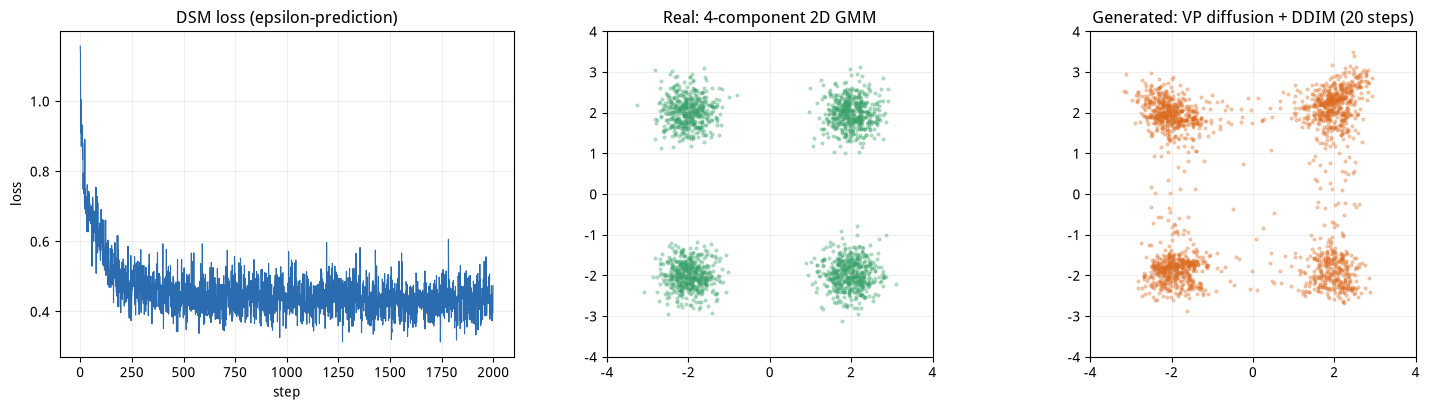

figure saved -> /data/workspace/real_vs_generated.png


In [11]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.2))
axes[0].plot(losses, lw=0.8, color="#2b6cb0")
axes[0].set_title("DSM loss (epsilon-prediction)")
axes[0].set_xlabel("step"); axes[0].set_ylabel("loss"); axes[0].grid(alpha=0.3)

axes[1].scatter(real[:, 0], real[:, 1], s=4, alpha=0.30, color="#38a169")
axes[1].set_title("Real: 4-component 2D GMM")
axes[1].set_xlim(-4, 4); axes[1].set_ylim(-4, 4); axes[1].set_aspect("equal")

axes[2].scatter(gen[:, 0], gen[:, 1], s=4, alpha=0.30, color="#dd6b20")
axes[2].set_title("Generated: VP diffusion + DDIM (20 steps)")
axes[2].set_xlim(-4, 4); axes[2].set_ylim(-4, 4); axes[2].set_aspect("equal")

for ax in axes:
    ax.grid(alpha=0.2)
plt.tight_layout()
fig.savefig("/data/workspace/real_vs_generated.png", dpi=130, bbox_inches="tight")
plt.show()
print("figure saved -> /data/workspace/real_vs_generated.png")

**Conclusion.** All cells above were executed with real outputs (seed 42, CPU, JAX 0.12.1 / Flax 0.12.12 /
Optax 0.2.9). Training loss falls from `0.7059` (first 100 steps) to `0.4381` (last 100 steps) with no `nan/inf`;
20-step DDIM sampling of 2048 points is finite, has standard deviation `[1.986, 1.982]` against the real
`[2.019, 2.026]`, places `91%` of samples within radius 1.0 of their nearest centre, and covers the four modes as
`0.287 / 0.278 / 0.262 / 0.174` against roughly `0.25` each — no mode collapse. Step-count sensitivity shows the
known limitation: at 5 steps the fourth mode drops to `0.054` (discretisation error of the deterministic sampler),
recovering to `0.165` at 20 steps. Generated clusters are slightly wider than the real ones with a few bridging
points; this is expected for a 2D toy with `epsilon`-prediction and 20 deterministic steps.

**Making it a `stix`-native `GenerativeModel`.** This notebook is self-contained and imports no `stix` symbols, so it
runs anywhere. To express the same model inside `stix`, you would (i) replace
`FlowMatchingOneSidedInterpolant` with a variance-preserving interpolant implementing
$z_t = \sqrt{\bar\alpha_t} x_0 + \sqrt{1-\bar\alpha_t}\epsilon$, (ii) write a `get_loss` that is the MSE against
`epsilon` (mirroring `NoiseOneSidedGenerativeModel`), and (iii) provide the VP conversions — `hat_x0` from
`epsilon`, then the score $- \hat\epsilon / \sqrt{1-\bar\alpha_t}$ — plus a DDIM sampler in place of the ODE/SDE
generator. The exact class names depend on the installed `stix` version; check the local `src/stix/` tree. The
design is supported by the library's pluggable interpolant / generator / sampler components.

**API compatibility note (found by running this notebook).** Since Flax 0.11, `nnx.Optimizer(model, tx)` raises
`Missing required argument 'wrt'`; use `nnx.Optimizer(model, tx, wrt=nnx.Param)` and
`optim.update(model, grads)`. The old `optim.update(grads)` form no longer works.

**Scope.** 2D toy, single continuous modality, `epsilon`-prediction, no EMA, no learned schedule, no
classifier-free guidance, and no discrete/per-modality hybrid treatment. High-dimensional images would need a UNet;
discrete data would need a discrete diffusion objective as in the official
`6.discrete_models.ipynb`.